# 03 · Evaluación final, sensibilidad y reducción de dimensión

¿Con qué fiabilidad se puede identificar una sesión que termina en compra? Continuamos la clasificación supervisada de `Revenue` con las particiones del 01 y las cinco configuraciones del 02. La proporción de compras da la referencia para precisión promedio (AP). Usamos validación para tomar decisiones y prueba para describir su efecto.

Sakar et al. (2019), Necula (2023), Satu e Islam (2023) y Lin (2025) estudiaron esta base con distintos métodos de balanceo y partición. Esa diferencia limita la comparación directa de sus cifras con las nuestras. La tabla resume los resultados publicados.

| Trabajo | Modelos y preparación | Evaluación | Resultado publicado |
|---|---|---|---|
| Sakar et al. (2019) | MLP, RF y SVM con sobremuestreo y selección de variables | El protocolo detallado no consta en la fuente consultada | MLP, exactitud 87,24 % y F1 0,86 |
| Necula (2023) | Regresión logística, árboles, RF y SVM con ADASYN y exploración mediante PCA | Diez pliegues y 25 % reservado para prueba | RF, ROC-AUC 0,9777 en CV y 0,8973 en prueba |
| Satu e Islam (2023) | RF, SVM, árboles y regresión logística con SMOTE, escalado y selección de variables | Diez pliegues en Weka | RF, exactitud 92,39 % y F1 0,924 |
| Lin (2025) | SVM, XGBoost, CatBoost y red neuronal con SMOTE y filtros de variables | Partición 80/20 con 50 semillas | CatBoost, precisión 0,934, recall 0,935 y ROC-AUC 0,985 |

La ejecución habitual vuelve a ajustar los cinco clasificadores y calcula sus curvas y umbrales. Calculamos los intervalos y las comparaciones sobre estas particiones. Las búsquedas sin PageValues y de reducción permiten reutilizar sus candidatos guardados.

In [1]:
from pathlib import Path
import hashlib
from importlib.metadata import version
from itertools import combinations

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.metrics import (
    ConfusionMatrixDisplay, average_precision_score, confusion_matrix,
    precision_recall_curve, roc_curve,
)
from sklearn.model_selection import cross_val_score
from threadpoolctl import threadpool_limits

from shopytics.evaluation import comparar, intervalos, intervalos_cv, replicas
from shopytics.reduction import pipeline_reducido
from shopytics.utils import SEMILLA
from shopytics.models import construir_modelos
from shopytics.search import mallas_ampliadas
from shopytics.training import buscar_configuraciones, evaluar, pliegues, validar_finalistas

REPETIR_SIN_PAGEVALUES = False
REPETIR_REDUCCION = False

raiz = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
datos = raiz / "data"
resultados = raiz / "resultados"
salida = resultados / "evaluacion"
salida.mkdir(exist_ok=True)
entrenamiento = resultados / "entrenamiento"
huella = hashlib.sha256((datos / "online_shoppers_intention.csv").read_bytes()).hexdigest()
particiones = pd.read_pickle(datos / "dataset_particiones.pkl")
X = {p: df.drop(columns="Revenue") for p, df in particiones.items()}
y = {p: df["Revenue"].astype(int) for p, df in particiones.items()}
tr, va, te = "entrenamiento", "validacion", "prueba"
mejores = pd.read_json(entrenamiento / "mejores_configuraciones.json").set_index("modelo")
familias = mejores.sort_values("AP", ascending=False).index
print("SHA-256:", huella, "· Semilla:", SEMILLA)
print({p: version(p) for p in ["numpy", "pandas", "scipy", "scikit-learn", "umap-learn", "numba"]})
display(pd.DataFrame({p: [len(y[p]), y[p].sum(), y[p].mean()] for p in y},
                     index=["Sesiones", "Compras", "Prevalencia"]).T)
display(mejores.loc[familias, ["params", "AP_CV", "AP"]])

SHA-256: d8e130ba51532985f93281a73ce299e6ce150cb915769a7962a11e595eadd6a1 · Semilla: 42
{'numpy': '2.3.1', 'pandas': '2.3.1', 'scipy': '1.16.3', 'scikit-learn': '1.7.2', 'umap-learn': '0.6.0', 'numba': '0.68.1'}


,Sesiones,Compras,Prevalencia
entrenamiento,7323.0,1145.0,0.156357
validacion,2441.0,381.0,0.156084
prueba,2441.0,382.0,0.156493


,params,AP_CV,AP
modelo,,,
RandomForest,"{'clf__class_weight': None, 'clf__max_depth': ...",0.757273,0.741404
MLP,"{'clf__alpha': 0.1, 'clf__hidden_layer_sizes':...",0.737548,0.722479
SVM,"{'clf__C': 30, 'clf__class_weight': None, 'clf...",0.725999,0.705417
kNN,"{'clf__n_neighbors': 81, 'clf__p': 2, 'clf__we...",0.717198,0.701832
Regresion_logistica,"{'clf__C': 0.1, 'clf__class_weight': None, 'pr...",0.689679,0.684086


## 1. Qué explica la selección del 02

El primer gráfico recupera la señal individual medida en entrenamiento. En los ocho paneles de la malla, cada punto promedia las configuraciones con ese valor del parámetro. Las barras muestran la dispersión entre los cinco promedios por pliegue.

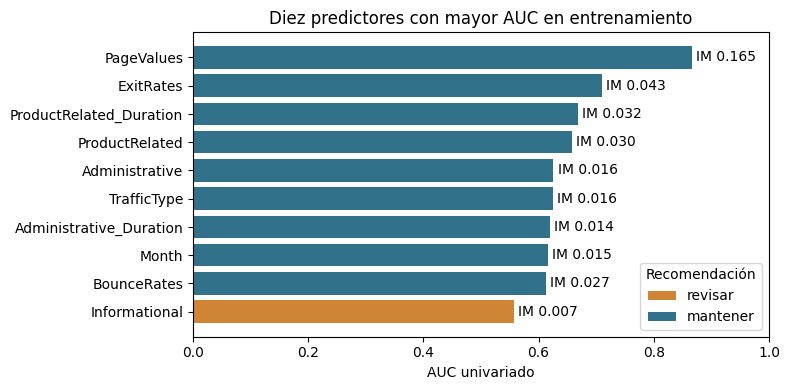

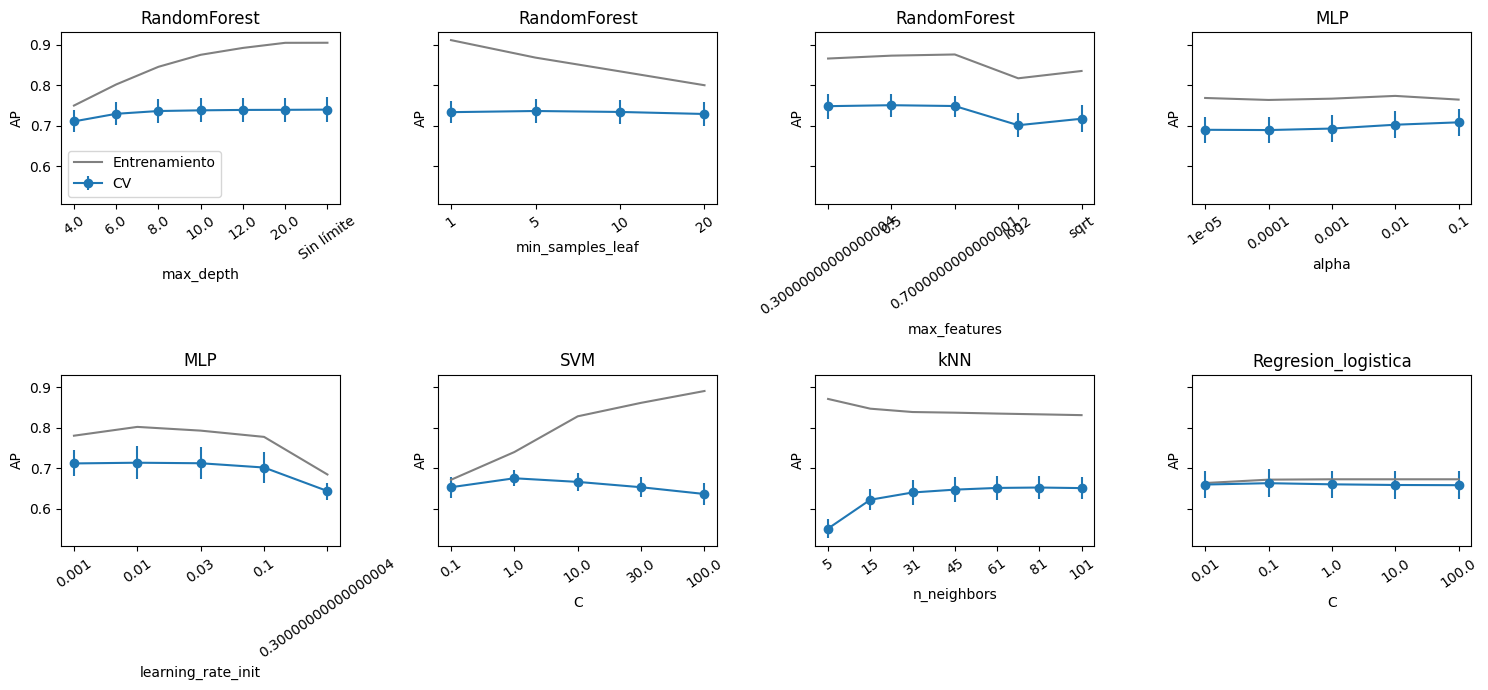

In [2]:
variables = pd.read_json(resultados / "variables" / "analisis_variables.json")
principales = variables.nlargest(10, "auc_univariado").sort_values("auc_univariado")
colores = {"mantener": "#31718a", "revisar": "#ce8534", "eliminar o combinar": "#a5a5a5"}
fig, ax = plt.subplots(figsize=(8, 4))
for recomendacion, grupo in principales.groupby("recomendacion", sort=False):
    posiciones = principales.index.get_indexer(grupo.index)
    barras = ax.barh(posiciones, grupo.auc_univariado, color=colores[recomendacion], label=recomendacion)
    ax.bar_label(barras, labels=[f"IM {valor:.3f}" for valor in grupo.informacion_mutua], padding=3)
ax.set(yticks=range(len(principales)), yticklabels=principales.variable,
       xlim=(0, 1), xlabel="AUC univariado", title="Diez predictores con mayor AUC en entrenamiento")
ax.legend(title="Recomendación", loc="lower right")
plt.tight_layout()
plt.show()

paneles = [("RandomForest", "max_depth"), ("RandomForest", "min_samples_leaf"),
           ("RandomForest", "max_features"), ("MLP", "alpha"), ("MLP", "learning_rate_init"),
           ("SVM", "C"), ("kNN", "n_neighbors"), ("Regresion_logistica", "C")]
fig, axes = plt.subplots(2, 4, figsize=(15, 7), sharey=True)
for ax, (familia, parametro) in zip(axes.flat, paneles):
    cv = pd.read_json(entrenamiento / "cv" / f"{familia}.json")
    parametros = pd.json_normalize(cv["params"])
    if familia == "SVM":
        cv = cv.loc[parametros["clf__kernel"].eq("rbf")]
    grupos = cv.groupby(parametros["clf__" + parametro].fillna("Sin límite"))
    validacion = grupos[[f"split{i}_test_score" for i in range(5)]].mean()
    ajuste = grupos[[f"split{i}_train_score" for i in range(5)]].mean()
    etiquetas = validacion.index.astype(str)
    ax.errorbar(etiquetas, validacion.mean(axis=1), yerr=validacion.std(axis=1), fmt="o-", label="CV")
    ax.plot(etiquetas, ajuste.mean(axis=1), color="gray", label="Entrenamiento")
    ax.set(title=familia, xlabel=parametro, ylabel="AP")
    ax.tick_params(axis="x", rotation=35)
axes[0, 0].legend()
fig.tight_layout()
plt.show()

## 2. Rendimiento de las cinco familias

Ajustamos cada pipeline sobre entrenamiento. Las métricas de clasificación usan el umbral nativo. Para las curvas y AP usamos la puntuación continua, incluida la función de decisión de SVM.

AP  ROC_AUC  precision  recall      F1  \
modelo              particion                                                   
RandomForest        entrenamiento  0.8284   0.9573     0.7977  0.6541  0.7188   
                    validacion     0.7414   0.9265     0.7025  0.5827  0.6370   
                    prueba         0.7496   0.9302     0.7443  0.5942  0.6608   
MLP                 entrenamiento  0.7798   0.9429     0.7500  0.6341  0.6872   
                    validacion     0.7225   0.9242     0.7161  0.5958  0.6504   
                    prueba         0.7494   0.9284     0.7157  0.5864  0.6446   
SVM                 entrenamiento  0.7986   0.9386     0.7745  0.6480  0.7057   
                    validacion     0.7054   0.9001     0.7013  0.5669  0.6270   
                    prueba         0.7272   0.9034     0.7210  0.6021  0.6562   
kNN                 entrenamiento  1.0000   1.0000     1.0000  1.0000  1.0000   
                    validacion     0.7018   0.9124     0.7266  0.4882  0.5840   
                    prueba         0.6976   0.9075     0.7346  0.5000  0.5950   
Regresion_logistica entrenamiento  0.6987   0.9194     0.7141  0.5520  0.6227   
                    validacion     0.6841   0.9123     0.7170  0.5853  0.6445   
                    prueba         0.6956   0.9110     0.7143  0.5497  0.6213   

                                   balanced_accuracy  accuracy  
modelo              particion                                   
RandomForest        entrenamiento             0.8117    0.9200  
                    validacion                0.7685    0.8964  
                    prueba                    0.7782    0.9045  
MLP                 entrenamiento             0.7974    0.9097  
                    validacion                0.7761    0.9000  
                    prueba                    0.7716    0.8988  
SVM                 entrenamiento             0.8065    0.9155  
                    validacion                0.7611    0.8947  
                    prueba                    0.7794    0.9013  
kNN                 entrenamiento             1.0000    1.0000  
                    validacion                0.7271    0.8914  
                    prueba                    0.7332    0.8935  
Regresion_logistica entrenamiento             0.7555    0.8954  
                    validacion                0.7713    0.8992  
                    prueba                    0.7545    0.8951

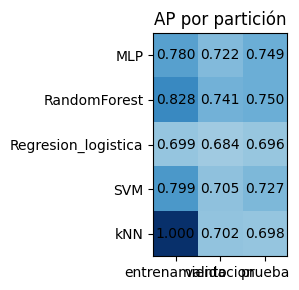

In [3]:
def puntuar(modelo, datos):
    if hasattr(modelo, "predict_proba"):
        return modelo.predict_proba(datos)[:, 1]
    return modelo.decision_function(datos)

modelos = construir_modelos()
puntuaciones = {}
filas = []
with threadpool_limits(limits=1):
    for familia in familias:
        modelo = modelos[familia].set_params(**mejores.at[familia, "params"])
        modelo.fit(X[tr], y[tr])
        for p in particiones:
            puntuaciones[familia, p] = puntuar(modelo, X[p])
            filas.append({"modelo": familia, "particion": p, **evaluar(modelo, X[p], y[p])})

metricas = pd.DataFrame(filas).set_index(["modelo", "particion"])
display(metricas.round(4))
ap = metricas.AP.unstack()[[tr, va, te]]
fig, ax = plt.subplots(figsize=(6, 3))
ax.imshow(ap, cmap="Blues", vmin=0.5, vmax=1)
ax.set(xticks=range(3), xticklabels=ap.columns, yticks=range(len(ap)), yticklabels=ap.index, title="AP por partición")
for i, fila in enumerate(ap.to_numpy()):
    for j, valor in enumerate(fila):
        ax.text(j, i, f"{valor:.3f}", ha="center", va="center")
plt.tight_layout()
plt.show()

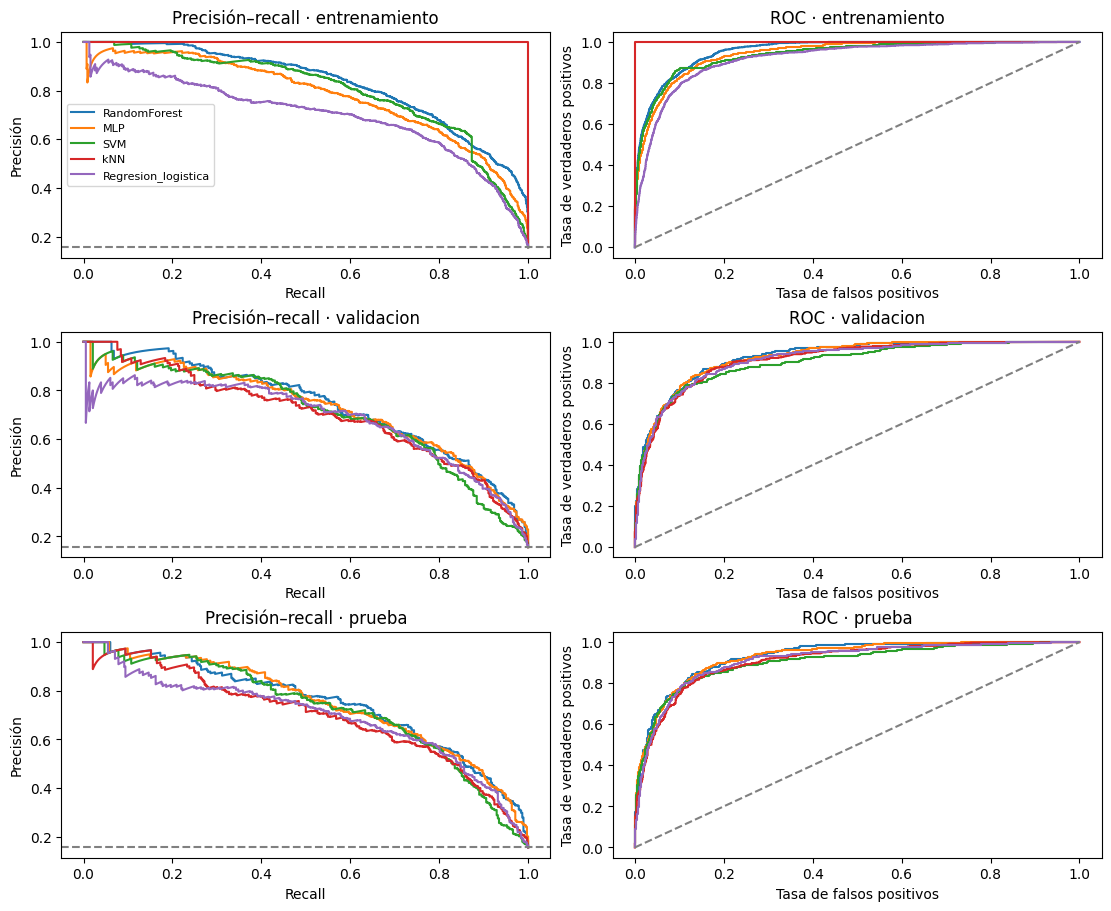

In [4]:
fig, axes = plt.subplots(len(particiones), 2, figsize=(11, 9), layout="constrained")
for p, (pr, roc) in zip(particiones, axes):
    for familia in familias:
        scores = puntuaciones[familia, p]
        precision, recall, _ = precision_recall_curve(y[p], scores)
        fpr, tpr, _ = roc_curve(y[p], scores)
        pr.plot(recall, precision, label=familia)
        roc.plot(fpr, tpr)
    pr.axhline(y[p].mean(), ls="--", color="gray")
    roc.plot([0, 1], [0, 1], "--", color="gray")
    pr.set(xlabel="Recall", ylabel="Precisión", title=f"Precisión–recall · {p}")
    roc.set(xlabel="Tasa de falsos positivos", ylabel="Tasa de verdaderos positivos", title=f"ROC · {p}")
axes[0, 0].legend(fontsize=8)
plt.show()

Los intervalos de CV usan la distribución *t* con cuatro grados de libertad. En las particiones, el bootstrap remuestrea por clase 2.000 veces con las predicciones fijas. Para comparar familias usa las mismas sesiones en cada réplica. Mostramos, en este orden, los intervalos de CV para AP, ROC-AUC y F1; los intervalos de AP por partición; las métricas de prueba con umbral nativo, cada una con su intervalo bootstrap; y las comparaciones pareadas de AP y ROC-AUC en prueba.

In [5]:
muestras = {}
filas_cv, filas_ic = [], []
with threadpool_limits(limits=1):
    for familia in familias:
        filas_cv.append(intervalos_cv(modelos[familia], X[tr], y[tr]).assign(modelo=familia))
        for p in particiones:
            muestra = replicas(y[p], puntuaciones[familia, p], 0 if familia == "SVM" else .5)
            muestras[familia, p] = muestra
            filas_ic.append(intervalos(muestra).assign(modelo=familia, particion=p))

ic_cv = pd.concat(filas_cv, ignore_index=True)
ic = pd.concat(filas_ic, ignore_index=True)
pares = pd.concat([comparar(muestras[a, te], muestras[b, te]).assign(modelo_a=a, modelo_b=b)
                   for a, b in combinations(familias, 2)], ignore_index=True)
display(ic_cv.set_index(["modelo", "metrica"]).round(4))
display(ic.query("metrica == 'AP'").round(4))
ic_prueba = ic.query("particion == @te").set_index(["modelo", "metrica"])
puntual = metricas.xs(te, level="particion")
display(pd.DataFrame({
    m: [f"{puntual.at[f, m]:.4f} [{ic_prueba.at[(f, m), 'ic_inferior']:.4f}, "
        f"{ic_prueba.at[(f, m), 'ic_superior']:.4f}]" for f in familias]
    for m in ["AP", "ROC_AUC", "F1", "precision", "recall", "balanced_accuracy"]
}, index=pd.Index(familias, name="modelo")))
display(pares.set_index(["modelo_a", "modelo_b", "metrica"]).round(4))

n_folds   media  desviacion  error_estandar  \
modelo              metrica                                                
RandomForest        AP             5  0.7573      0.0262          0.0117   
                    ROC_AUC        5  0.9340      0.0076          0.0034   
                    F1             5  0.6649      0.0343          0.0153   
MLP                 AP             5  0.7375      0.0382          0.0171   
                    ROC_AUC        5  0.9280      0.0101          0.0045   
                    F1             5  0.6391      0.0555          0.0248   
SVM                 AP             5  0.7260      0.0393          0.0176   
                    ROC_AUC        5  0.9032      0.0193          0.0086   
                    F1             5  0.6580      0.0498          0.0223   
kNN                 AP             5  0.7172      0.0259          0.0116   
                    ROC_AUC        5  0.9180      0.0095          0.0043   
                    F1             5  0.5760      0.0515          0.0230   
Regresion_logistica AP             5  0.6897      0.0357          0.0160   
                    ROC_AUC        5  0.9158      0.0085          0.0038   
                    F1             5  0.6164      0.0297          0.0133   

                             ic_inferior  ic_superior  
modelo              metrica                            
RandomForest        AP            0.7248       0.7898  
                    ROC_AUC       0.9245       0.9435  
                    F1            0.6224       0.7074  
MLP                 AP            0.6901       0.7850  
                    ROC_AUC       0.9155       0.9406  
                    F1            0.5702       0.7079  
SVM                 AP            0.6772       0.7748  
                    ROC_AUC       0.8793       0.9271  
                    F1            0.5961       0.7198  
kNN                 AP            0.6850       0.7494  
                    ROC_AUC       0.9061       0.9298  
                    F1            0.5121       0.6399  
Regresion_logistica AP            0.6453       0.7341  
                    ROC_AUC       0.9052       0.9264  
                    F1            0.5796       0.6533

,metrica,media_bootstrap,ic_inferior,ic_superior,modelo,particion
0,AP,0.8283,0.8105,0.8448,RandomForest,entrenamiento
7,AP,0.7427,0.7034,0.7786,RandomForest,validacion
14,AP,0.7505,0.7134,0.7869,RandomForest,prueba
21,AP,0.7799,0.7562,0.8010,MLP,entrenamiento
28,AP,0.7240,0.6808,0.7653,MLP,validacion
35,AP,0.7504,0.7127,0.7873,MLP,prueba
42,AP,0.7986,0.7767,0.8183,SVM,entrenamiento
49,AP,0.7072,0.6634,0.7490,SVM,validacion
56,AP,0.7282,0.6864,0.7689,SVM,prueba
63,AP,1.0000,1.0000,1.0000,kNN,entrenamiento


,AP,ROC_AUC,F1,precision,recall,balanced_accuracy
modelo,,,,,,
RandomForest,"0.7496 [0.7134, 0.7869]","0.9302 [0.9178, 0.9430]","0.6608 [0.6211, 0.6984]","0.7443 [0.7006, 0.7886]","0.5942 [0.5445, 0.6414]","0.7782 [0.7534, 0.8016]"
MLP,"0.7494 [0.7127, 0.7873]","0.9284 [0.9150, 0.9410]","0.6446 [0.6040, 0.6838]","0.7157 [0.6715, 0.7613]","0.5864 [0.5392, 0.6361]","0.7716 [0.7475, 0.7962]"
SVM,"0.7272 [0.6864, 0.7689]","0.9034 [0.8850, 0.9212]","0.6562 [0.6161, 0.6938]","0.7210 [0.6785, 0.7675]","0.6021 [0.5524, 0.6492]","0.7794 [0.7554, 0.8030]"
kNN,"0.6976 [0.6561, 0.7392]","0.9075 [0.8923, 0.9232]","0.5950 [0.5507, 0.6379]","0.7346 [0.6875, 0.7836]","0.5000 [0.4503, 0.5497]","0.7332 [0.7077, 0.7580]"
Regresion_logistica,"0.6956 [0.6541, 0.7396]","0.9110 [0.8950, 0.9272]","0.6213 [0.5778, 0.6647]","0.7143 [0.6688, 0.7621]","0.5497 [0.5000, 0.5995]","0.7545 [0.7288, 0.7807]"


media_bootstrap  ic_inferior  \
modelo_a     modelo_b            metrica                                 
RandomForest MLP                 AP                0.0002      -0.0190   
                                 ROC_AUC           0.0019      -0.0036   
             SVM                 AP                0.0223       0.0001   
                                 ROC_AUC           0.0270       0.0144   
             kNN                 AP                0.0515       0.0304   
                                 ROC_AUC           0.0226       0.0151   
             Regresion_logistica AP                0.0531       0.0244   
                                 ROC_AUC           0.0191       0.0107   
MLP          SVM                 AP                0.0221       0.0068   
                                 ROC_AUC           0.0251       0.0130   
             kNN                 AP                0.0514       0.0293   
                                 ROC_AUC           0.0207       0.0130   
             Regresion_logistica AP                0.0529       0.0268   
                                 ROC_AUC           0.0172       0.0091   
SVM          kNN                 AP                0.0292       0.0036   
                                 ROC_AUC          -0.0044      -0.0200   
             Regresion_logistica AP                0.0308       0.0051   
                                 ROC_AUC          -0.0079      -0.0224   
kNN          Regresion_logistica AP                0.0015      -0.0272   
                                 ROC_AUC          -0.0035      -0.0141   

                                          ic_superior  diferencia_puntual  \
modelo_a     modelo_b            metrica                                    
RandomForest MLP                 AP            0.0190              0.0002   
                                 ROC_AUC       0.0075              0.0018   
             SVM                 AP            0.0450              0.0224   
                                 ROC_AUC       0.0406              0.0268   
             kNN                 AP            0.0737              0.0520   
                                 ROC_AUC       0.0307              0.0227   
             Regresion_logistica AP            0.0812              0.0539   
                                 ROC_AUC       0.0289              0.0192   
MLP          SVM                 AP            0.0379              0.0222   
                                 ROC_AUC       0.0382              0.0249   
             kNN                 AP            0.0735              0.0518   
                                 ROC_AUC       0.0295              0.0209   
             Regresion_logistica AP            0.0801              0.0537   
                                 ROC_AUC       0.0261              0.0174   
SVM          kNN                 AP            0.0543              0.0296   
                                 ROC_AUC       0.0102             -0.0041   
             Regresion_logistica AP            0.0567              0.0316   
                                 ROC_AUC       0.0062             -0.0076   
kNN          Regresion_logistica AP            0.0298              0.0019   
                                 ROC_AUC       0.0069             -0.0035   

                                          n_boot  
modelo_a     modelo_b            metrica          
RandomForest MLP                 AP         2000  
                                 ROC_AUC    2000  
             SVM                 AP         2000  
                                 ROC_AUC    2000  
             kNN                 AP         2000  
                                 ROC_AUC    2000  
             Regresion_logistica AP         2000  
                                 ROC_AUC    2000  
MLP          SVM                 AP         2000  
                                 ROC_AUC    2000  
             kNN                 AP         2000  
                                 ROC_AUC    2000  
    

## 3. ¿Qué cambia al elegir el umbral por F1?

Maximizamos F1 en validación. En caso de empate tomamos el menor umbral. Aplicamos ese valor en prueba y calculamos intervalos estratificados para precisión, recall, F1 y exactitud balanceada a partir de los conteos de la matriz de confusión.

umbral                precisión  \
modelo              regla                                                 
RandomForest        Nativo            0.500000  0.7443 [0.6994, 0.7873]   
                    F1 en validación  0.319528  0.6505 [0.6130, 0.6889]   
MLP                 Nativo            0.500000  0.7157 [0.6711, 0.7615]   
                    F1 en validación  0.433714  0.6818 [0.6411, 0.7225]   
SVM                 Nativo            0.000000  0.7210 [0.6774, 0.7662]   
                    F1 en validación -0.697044  0.6345 [0.5982, 0.6723]   
kNN                 Nativo            0.500000  0.7346 [0.6873, 0.7842]   
                    F1 en validación  0.398862  0.6547 [0.6126, 0.6970]   
Regresion_logistica Nativo            0.500000  0.7143 [0.6698, 0.7607]   
                    F1 en validación  0.317197  0.6337 [0.5939, 0.6727]   

                                                       recall  \
modelo              regla                                       
RandomForest        Nativo            0.5942 [0.5471, 0.6440]   
                    F1 en validación  0.7356 [0.6911, 0.7776]   
MLP                 Nativo            0.5864 [0.5366, 0.6361]   
                    F1 en validación  0.6675 [0.6230, 0.7147]   
SVM                 Nativo            0.6021 [0.5550, 0.6518]   
                    F1 en validación  0.7225 [0.6780, 0.7670]   
kNN                 Nativo            0.5000 [0.4503, 0.5497]   
                    F1 en validación  0.6204 [0.5732, 0.6702]   
Regresion_logistica Nativo            0.5497 [0.5000, 0.5995]   
                    F1 en validación  0.6885 [0.6440, 0.7356]   

                                         exactitud balanceada  \
modelo              regla                                       
RandomForest        Nativo            0.7782 [0.7541, 0.8040]   
                    F1 en validación  0.8311 [0.8087, 0.8532]   
MLP                 Nativo            0.7716 [0.7469, 0.7973]   
                    F1 en validación  0.8049 [0.7819, 0.8293]   
SVM                 Nativo            0.7794 [0.7548, 0.8044]   
                    F1 en validación  0.8226 [0.7997, 0.8459]   
kNN                 Nativo            0.7332 [0.7084, 0.7580]   
                    F1 en validación  0.7799 [0.7554, 0.8051]   
Regresion_logistica Nativo            0.7545 [0.7297, 0.7804]   
                    F1 en validación  0.8073 [0.7835, 0.8313]   

                                                           F1  
modelo              regla                                      
RandomForest        Nativo            0.6608 [0.6195, 0.7003]  
                    F1 en validación  0.6904 [0.6569, 0.7236]  
MLP                 Nativo            0.6446 [0.6030, 0.6865]  
                    F1 en validación  0.6746 [0.6381, 0.7110]  
SVM                 Nativo            0.6562 [0.6154, 0.6960]  
                    F1 en validación  0.6756 [0.6416, 0.7091]  
kNN                 Nativo            0.5950 [0.5508, 0.6373]  
                    F1 en validación  0.6371 [0.5987, 0.6756]  
Regresion_logistica Nativo            0.6213 [0.5786, 0.6638]  
                    F1 en validación  0.6600 [0.6239, 0.6954]

VN   FP   FN    VP
modelo              particion                          
RandomForest        entrenamiento  5988  190  396   749
                    validacion     1966   94  159   222
                    prueba         1981   78  155   227
MLP                 entrenamiento  5936  242  419   726
                    validacion     1970   90  154   227
                    prueba         1970   89  158   224
SVM                 entrenamiento  5962  216  403   742
                    validacion     1968   92  165   216
                    prueba         1970   89  152   230
kNN                 entrenamiento  6178    0    0  1145
                    validacion     1990   70  195   186
                    prueba         1990   69  191   191
Regresion_logistica entrenamiento  5925  253  513   632
                    validacion     1972   88  158   223
                    prueba         1975   84  172   210

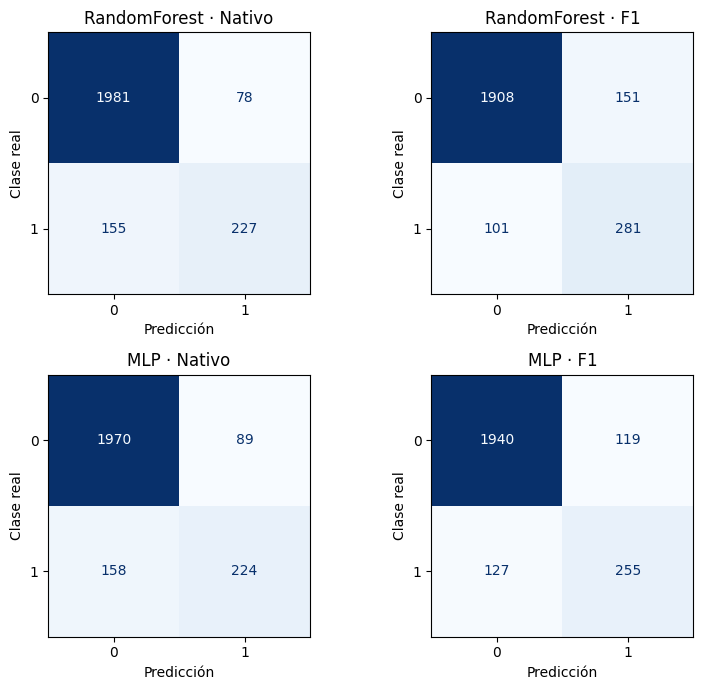

In [6]:
def resumen_umbral(y_real, scores, umbral):
    tn, fp, fn, tp = confusion_matrix(y_real, scores >= umbral, labels=[0, 1]).ravel()
    rng = np.random.default_rng(SEMILLA)
    # Dentro de cada clase, remuestrear las decisiones binarias da una binomial.
    tp_b = rng.binomial(tp + fn, tp / (tp + fn), 2000)
    fp_b = rng.binomial(tn + fp, fp / (tn + fp), 2000)
    aciertos, falsas = np.r_[tp, tp_b], np.r_[fp, fp_b]
    precision = np.divide(aciertos, aciertos + falsas, out=np.zeros(len(aciertos)), where=aciertos + falsas > 0)
    sensibilidad = aciertos / (tp + fn)
    especificidad = 1 - falsas / (tn + fp)
    medidas = {"precisión": precision, "recall": sensibilidad,
               "exactitud balanceada": (sensibilidad + especificidad) / 2,
               "F1": 2 * aciertos / (aciertos + falsas + tp + fn)}
    return {k: f"{v[0]:.4f} [{np.quantile(v[1:], .025):.4f}, {np.quantile(v[1:], .975):.4f}]"
            for k, v in medidas.items()}

umbrales = {}
filas = []
for familia in familias:
    precision, recall, cortes = precision_recall_curve(y[va], puntuaciones[familia, va])
    f1 = 2 * precision * recall / np.maximum(precision + recall, np.finfo(float).eps)
    umbrales[familia] = cortes[f1[:-1].argmax()]
    nativo = 0 if familia == "SVM" else 0.5
    for regla, corte in [("Nativo", nativo), ("F1 en validación", umbrales[familia])]:
        filas.append({"modelo": familia, "regla": regla, "umbral": corte,
                      **resumen_umbral(y[te], puntuaciones[familia, te], corte)})
display(pd.DataFrame(filas).set_index(["modelo", "regla"]))

conteos = []
for familia in familias:
    for p in particiones:
        pred = puntuaciones[familia, p] >= (0 if familia == "SVM" else .5)
        tn, fp, fn, tp = confusion_matrix(y[p], pred, labels=[0, 1]).ravel()
        conteos.append(dict(modelo=familia, particion=p, VN=tn, FP=fp, FN=fn, VP=tp))
display(pd.DataFrame(conteos).set_index(["modelo", "particion"]))

fig, axes = plt.subplots(2, 2, figsize=(8, 7))
for familia, fila in zip(familias[:2], axes):
    for ax, (regla, corte) in zip(fila, [("Nativo", 0 if familia == "SVM" else .5), ("F1", umbrales[familia])]):
        ConfusionMatrixDisplay.from_predictions(y[te], puntuaciones[familia, te] >= corte,
                                                colorbar=False, ax=ax, cmap="Blues")
        ax.set(title=f"{familia} · {regla}", xlabel="Predicción", ylabel="Clase real")
plt.tight_layout()
plt.show()

En Random Forest el umbral elegido recupera 54 compras adicionales en prueba (227 a 281) y produce 73 falsos positivos adicionales (78 a 151). La conveniencia de ese cambio depende del coste de contactar a un visitante y del valor de detectar una compra.

## 4. Sensibilidad a PageValues y SpecialDay

Para PageValues repetimos el protocolo del 02 sin esa columna. Cada familia vuelve a competir en su malla y se elige por AP de validación entre sus tres finalistas de CV. La ruta habitual lee los quince finalistas del barrido archivado.

In [7]:
if REPETIR_SIN_PAGEVALUES:
    modelos_sin = construir_modelos(incluir_pagevalues=False)
    _, mallas = mallas_ampliadas()
    tablas = []
    with threadpool_limits(limits=1):
        for familia, modelo in modelos_sin.items():
            cv = buscar_configuraciones(modelo, mallas[familia], X[tr], y[tr])
            tabla = validar_finalistas(modelo, cv, X[tr], y[tr], X[va], y[va])
            tablas.append(tabla.assign(modelo=familia))
    finalistas = pd.concat(tablas, ignore_index=True)
    finalistas.to_json(salida / "finalistas_sin_pagevalues.json", orient="records", indent=2, double_precision=15)
else:
    finalistas = pd.read_json(salida / "finalistas_sin_pagevalues.json", precise_float=True)

sin_pv = finalistas.loc[finalistas.groupby("modelo").AP.idxmax()].set_index("modelo")
pv = mejores[["AP"]].rename(columns={"AP": "AP_con"}).join(
    sin_pv[["AP", "ROC_AUC", "params"]].rename(columns={"AP": "AP_sin", "ROC_AUC": "ROC_AUC_sin"}))
display(pv.assign(delta_con_menos_sin=pv.AP_con - pv.AP_sin).round(4))

,AP_con,AP_sin,ROC_AUC_sin,params,delta_con_menos_sin
modelo,,,,,
RandomForest,0.7414,0.3848,0.7847,"{'clf__class_weight': 'balanced', 'clf__max_de...",0.3566
MLP,0.7225,0.3532,0.7653,"{'clf__alpha': 0.1, 'clf__hidden_layer_sizes':...",0.3693
SVM,0.7054,0.3403,0.7685,"{'clf__C': 1, 'clf__class_weight': 'balanced',...",0.3652
kNN,0.7018,0.3477,0.7615,"{'clf__n_neighbors': 101, 'clf__p': 1, 'clf__w...",0.3541
Regresion_logistica,0.6841,0.3345,0.7616,"{'clf__C': 0.1, 'clf__class_weight': None, 'pr...",0.3496


En SpecialDay fijamos la configuración del 02 para aislar dos cambios distintos. Medimos el efecto de quitar la columna y el de pasar de proximidad numérica a one-hot. Los seis niveles equidistantes tienen la misma representación estandarizada si se codifican por rango ordinal. Completamos la comparación con el AP mensual del ganador en validación.

In [8]:
sin_sd = construir_modelos(incluir_specialday=False)
onehot = construir_modelos(codificar_specialday="onehot")
filas = []
with threadpool_limits(limits=1):
    for familia in familias:
        variantes = {"sin": sin_sd[familia], "onehot": onehot[familia]}
        fila = {"modelo": familia, "numérico": metricas.at[(familia, va), "AP"]}
        for nombre, modelo in variantes.items():
            modelo.set_params(**mejores.at[familia, "params"]).fit(X[tr], y[tr])
            fila[nombre] = average_precision_score(y[va], puntuar(modelo, X[va]))
        fila["AP_CV_numerico"] = ic_cv.query("modelo == @familia and metrica == 'AP'").media.item()
        fila["AP_CV_onehot"] = cross_val_score(onehot[familia], X[tr], y[tr], cv=pliegues(),
                                               scoring="average_precision", error_score="raise").mean()
        filas.append(fila)
sd = pd.DataFrame(filas).set_index("modelo")
sd["con_menos_sin"] = sd["numérico"] - sd["sin"]
sd["onehot_menos_numérico"] = sd["onehot"] - sd["numérico"]
display(sd.round(4))
ganador = familias[0]
mensual = pd.DataFrame({"mes": X[va]["Month"], "compra": y[va], "score": puntuaciones[ganador, va]})
filas = [{"mes": mes, "sesiones": len(grupo), "compras": grupo.compra.sum(),
          "AP": average_precision_score(grupo.compra, grupo.score) if grupo.compra.any() else np.nan}
         for mes, grupo in mensual.groupby("mes")]
display(pd.DataFrame(filas).set_index("mes").round(4))

,numérico,sin,onehot,AP_CV_numerico,AP_CV_onehot,con_menos_sin,onehot_menos_numérico
modelo,,,,,,,
RandomForest,0.7414,0.7418,0.7418,0.7573,0.7556,-0.0004,0.0004
MLP,0.7225,0.7181,0.7322,0.7375,0.7365,0.0044,0.0097
SVM,0.7054,0.7040,0.6988,0.7260,0.7287,0.0014,-0.0066
kNN,0.7018,0.7066,0.7065,0.7172,0.7216,-0.0048,0.0046
Regresion_logistica,0.6841,0.6845,0.6835,0.6897,0.6907,-0.0004,-0.0006


,sesiones,compras,AP
mes,,,
Aug,76,8,0.5680
Dec,334,41,0.7670
Feb,37,0,NaN
Jul,96,15,0.5983
June,58,7,0.6900
Mar,359,38,0.7853
May,663,74,0.8769
Nov,633,166,0.6826
Oct,98,15,0.5891


### Ablación con hiperparámetros fijos

Para el ganador del 02 medimos el efecto de retirar cada variable conservando la configuración seleccionada. Evaluamos el ajuste en entrenamiento y validación.

In [9]:
filas = []
with threadpool_limits(limits=1):
    for variable, opciones in [("PageValues", {"incluir_pagevalues": False}),
                              ("SpecialDay", {"incluir_specialday": False})]:
        modelo = construir_modelos(**opciones)[ganador].set_params(**mejores.at[ganador, "params"])
        modelo.fit(X[tr], y[tr])
        for p in (tr, va):
            filas.append(dict(variable=variable, modelo=ganador, particion=p, **evaluar(modelo, X[p], y[p])))
ablaciones_fijas = pd.DataFrame(filas)
display(ablaciones_fijas.set_index(["variable", "modelo", "particion"]).round(4))

AP  ROC_AUC  precision  recall  \
variable   modelo       particion                                           
PageValues RandomForest entrenamiento  0.5214   0.8578     0.7680  0.1214   
                        validacion     0.3785   0.7840     0.4462  0.0761   
SpecialDay RandomForest entrenamiento  0.8279   0.9571     0.8006  0.6594   
                        validacion     0.7418   0.9271     0.7111  0.5879   

                                           F1  balanced_accuracy  accuracy  
variable   modelo       particion                                           
PageValues RandomForest entrenamiento  0.2097             0.5573    0.8569  
                        validacion     0.1300             0.5293    0.8410  
SpecialDay RandomForest entrenamiento  0.7232             0.8145    0.9211  
                        validacion     0.6437             0.7719    0.8984

## 5. PCA y UMAP en las dos familias mejor clasificadas

La base tiene 73 columnas después de la codificación. Para cada candidato, la validación cruzada ajusta el preprocesador y el reductor dentro de cada pliegue. UMAP aprende únicamente de los predictores. La variante PCA de 0,95 retiene el 95 % de varianza y puede tener distinta dimensión efectiva en cada ajuste.

In [10]:
from itertools import product

def barrer_reduccion():
    filas = []
    for familia in familias[:2]:
        candidatos = [("PCA", n, None) for n in [5, 10, 15, 20, 28, 35, 45, .95]]
        candidatos += [("UMAP", n, k) for n, k in product([2, 5, 10, 15, 20], [15, 30, 50])]
        for metodo, n, k in candidatos:
            pipe = pipeline_reducido(modelos[familia], metodo, n, k)
            folds = cross_val_score(pipe, X[tr], y[tr], scoring="average_precision", cv=pliegues(),
                                    error_score="raise")
            pipe.fit(X[tr], y[tr])
            filas.append({"modelo": familia, "metodo": metodo, "dimensiones_solicitadas": n,
                          "componentes": pipe["reduccion"].n_components_ if metodo == "PCA" else n,
                          "vecinos": k, "AP_CV": folds.mean(), "std_CV": folds.std(),
                          "AP": average_precision_score(y[va], puntuar(pipe, X[va]))})
    return pd.DataFrame(filas)

if REPETIR_REDUCCION:
    with threadpool_limits(limits=1):
        barrido = barrer_reduccion()
    barrido.to_pickle(salida / "barrido_reduccion.pkl")
else:
    barrido = pd.read_pickle(salida / "barrido_reduccion.pkl")

def elegir_1se(grupo):
    grupo = grupo.assign(fraccion=grupo.dimensiones_solicitadas < 1)
    mejor = grupo.sort_values(["AP", "componentes", "fraccion"], ascending=[False, True, True]).iloc[0]
    corte = mejor.AP - mejor.std_CV / np.sqrt(5)
    elegibles = grupo.loc[grupo.AP >= corte - 1e-12]
    return elegibles.sort_values(["componentes", "fraccion", "AP"], ascending=[True, True, False]).iloc[0]

elegidos = pd.DataFrame([elegir_1se(grupo) for _, grupo in barrido.groupby(["modelo", "metodo"])])
columnas = ["modelo", "metodo", "componentes", "vecinos", "AP_CV", "AP"]
display(elegidos[columnas].round(4))

,modelo,metodo,componentes,vecinos,AP_CV,AP
28,MLP,PCA,15.0,NaN,0.7368,0.7219
38,MLP,UMAP,5.0,30.0,0.6739,0.6484
2,RandomForest,PCA,10.0,NaN,0.7198,0.7074
20,RandomForest,UMAP,15.0,50.0,0.6980,0.6959


La regla 1-SE admite candidatos a un error estándar del mejor AP de validación y elige la menor dimensión elegible. Los siguientes gráficos muestran cuánto cuesta comprimir, cómo cambia la validación con la dimensión y qué solapamiento de clases queda en dos dimensiones.

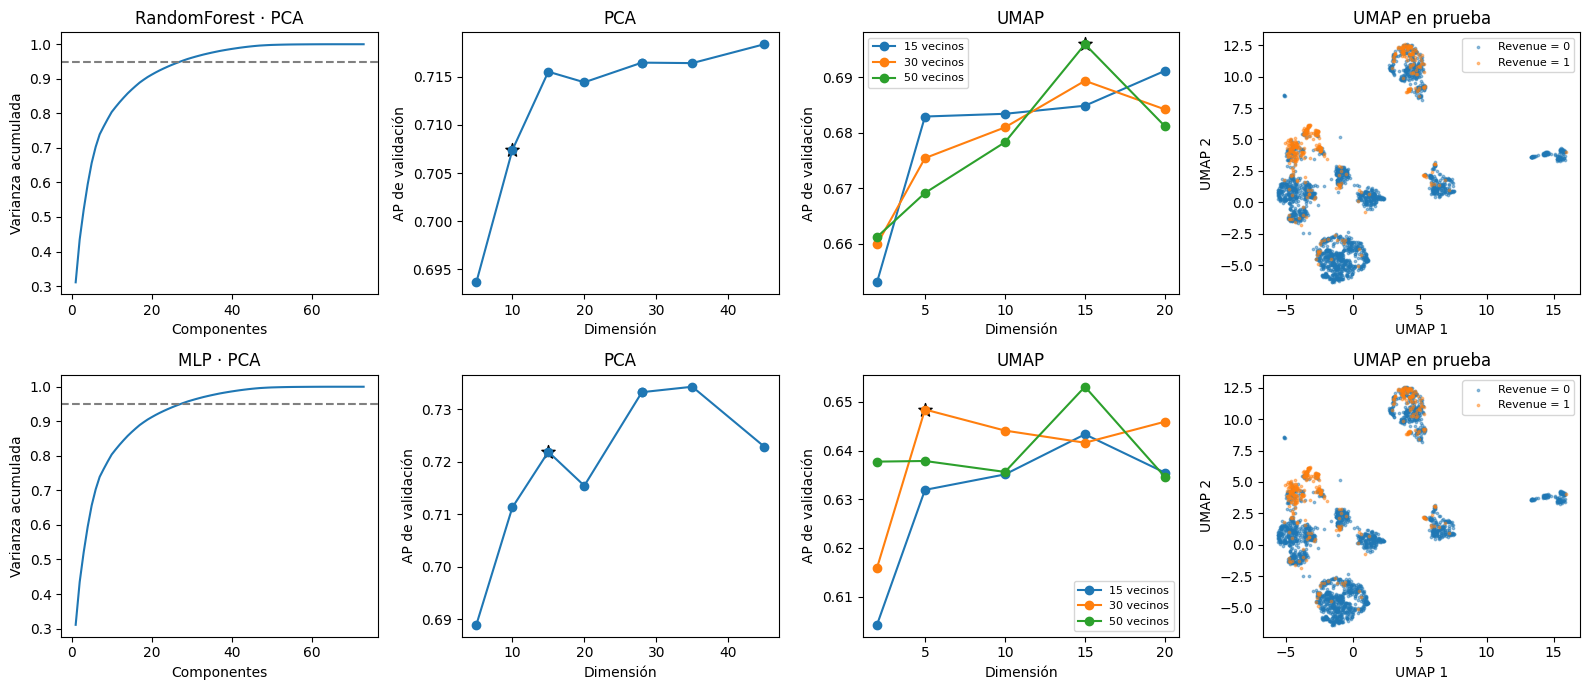

In [11]:
curvas, coordenadas, pruebas, comparaciones = [], [], [], []
with threadpool_limits(limits=1):
    for familia in familias[:2]:
        base = modelos[familia]
        pca = PCA(svd_solver="full").fit(base["pre"].transform(X[tr]))
        curvas.append(pd.DataFrame({"modelo": familia, "componente": np.arange(1, 1 + pca.n_components_),
                                    "varianza_explicada": pca.explained_variance_ratio_,
                                    "varianza_acumulada": pca.explained_variance_ratio_.cumsum()}))
        variantes = {"Base": muestras[familia, te]}
        seleccion = elegidos.query("modelo == @familia")
        ajustes = [(v.metodo, v.dimensiones_solicitadas, v.vecinos) for v in seleccion.itertuples()]
        for metodo, n, k in ajustes + [("UMAP2D", 2, 15)]:
            pipe = pipeline_reducido(base, "UMAP" if metodo == "UMAP2D" else metodo, n, k)
            pipe.fit(X[tr], y[tr])
            variantes[metodo] = replicas(y[te], puntuar(pipe, X[te]), 0 if familia == "SVM" else .5)
            if metodo == "UMAP2D":
                xy = pipe[:-1].transform(X[te])
                coordenadas.append(pd.DataFrame({"modelo": familia, "indice": X[te].index,
                                                  "x": xy[:, 0], "y": xy[:, 1], "y_true": y[te].to_numpy()}))
        for metodo, muestra in variantes.items():
            fila = dict(modelo=familia, metodo=metodo, **muestra.iloc[0])
            for ic_m in intervalos(muestra).itertuples():
                fila[f"ic_{ic_m.metrica}_inferior"] = ic_m.ic_inferior
                fila[f"ic_{ic_m.metrica}_superior"] = ic_m.ic_superior
            pruebas.append(fila)
            if metodo != "Base":
                comparaciones.append(comparar(muestra, variantes["Base"]).assign(modelo=familia, metodo=metodo))

varianza = pd.concat(curvas, ignore_index=True)
proyeccion = pd.concat(coordenadas, ignore_index=True)
prueba_red = pd.DataFrame(pruebas)
diferencias = pd.concat(comparaciones, ignore_index=True)
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for familia, (ax_var, ax_pca, ax_umap, ax_2d) in zip(familias[:2], axes):
    curva = varianza.loc[varianza.modelo == familia]
    ax_var.plot(curva.componente, curva.varianza_acumulada)
    ax_var.axhline(.95, ls="--", color="gray")
    ax_var.set(title=f"{familia} · PCA", xlabel="Componentes", ylabel="Varianza acumulada")
    candidatos = barrido.loc[barrido.modelo == familia]
    pca = candidatos.query("metodo == 'PCA'").sort_values("componentes")
    ax_pca.plot(pca.componentes, pca.AP, "o-")
    for k, grupo in candidatos.query("metodo == 'UMAP'").groupby("vecinos"):
        grupo = grupo.sort_values("componentes")
        ax_umap.plot(grupo.componentes, grupo.AP, "o-", label=f"{k:g} vecinos")
    for metodo, ax in [("PCA", ax_pca), ("UMAP", ax_umap)]:
        punto = elegidos.query("modelo == @familia and metodo == @metodo")
        ax.scatter(punto.componentes, punto.AP, marker="*", color="black", s=100)
        ax.set(title=metodo, xlabel="Dimensión", ylabel="AP de validación")
    ax_umap.legend(fontsize=8)
    for clase, grupo in proyeccion.query("modelo == @familia").groupby("y_true"):
        ax_2d.scatter(grupo.x, grupo.y, s=3, alpha=.45, label=f"Revenue = {clase}")
    ax_2d.set(title="UMAP en prueba", xlabel="UMAP 1", ylabel="UMAP 2")
    ax_2d.legend(fontsize=8)
plt.tight_layout()
plt.show()

### Evaluación de las variantes fijadas

En prueba comparamos la base, la variante seleccionada de cada método y la proyección UMAP 2D. La diferencia pareada de AP cuantifica el efecto de la reducción sobre las mismas sesiones.

In [12]:
display(prueba_red.set_index(["modelo", "metodo"])[
    ["AP", "ic_AP_inferior", "ic_AP_superior", "ROC_AUC", "F1"]].round(4))
display(diferencias.set_index(["modelo", "metodo", "metrica"])[
    ["diferencia_puntual", "ic_inferior", "ic_superior"]
].sort_index().round(4))

AP  ic_AP_inferior  ic_AP_superior  ROC_AUC      F1
modelo       metodo                                                         
RandomForest Base    0.7496          0.7134          0.7869   0.9302  0.6608
             PCA     0.7236          0.6831          0.7626   0.9134  0.6145
             UMAP    0.6841          0.6423          0.7257   0.8906  0.5826
             UMAP2D  0.6443          0.6007          0.6881   0.8850  0.5452
MLP          Base    0.7494          0.7127          0.7873   0.9284  0.6446
             PCA     0.7408          0.7027          0.7803   0.9255  0.6424
             UMAP    0.6365          0.5947          0.6809   0.8611  0.5429
             UMAP2D  0.5621          0.5172          0.6181   0.8531  0.5320

diferencia_puntual  ic_inferior  ic_superior
modelo       metodo metrica                                              
MLP          PCA    AP                  -0.0086      -0.0219       0.0050
                    ROC_AUC             -0.0029      -0.0084       0.0030
             UMAP   AP                  -0.1129      -0.1428      -0.0830
                    ROC_AUC             -0.0673      -0.0824      -0.0519
             UMAP2D AP                  -0.1873      -0.2242      -0.1428
                    ROC_AUC             -0.0753      -0.0908      -0.0597
RandomForest PCA    AP                  -0.0260      -0.0438      -0.0090
                    ROC_AUC             -0.0167      -0.0246      -0.0093
             UMAP   AP                  -0.0655      -0.0937      -0.0377
                    ROC_AUC             -0.0396      -0.0521      -0.0277
             UMAP2D AP                  -0.1053      -0.1365      -0.0740
                    ROC_AUC             -0.0451      -0.0586      -0.0325

## 6. Conclusiones y alcance

- **Selección.** Random Forest gana en validación (AP 0,7414). En prueba alcanza 0,7496 frente a 0,7494 de MLP. El intervalo pareado de la diferencia incluye cero. La evidencia deja margen para elegir entre ambas familias según el coste operativo.
- **Disponibilidad de variables.** Sin PageValues, aun reajustando la malla, el AP de validación de Random Forest cae a 0,3848. Para actuar durante una sesión haría falta evaluar predictores disponibles en el instante de la decisión. Los cambios al retirar SpecialDay son pequeños y dependen de la familia.
- **Simplificación.** En el 02, quitar seis predictores de bajo AUC individual dejó el AP de validación de RF prácticamente igual y mejoró el de MLP. Aquí, el 95 % de varianza requiere 28 componentes, mientras que la regla predictiva selecciona 10 para RF y 15 para MLP. UMAP pierde AP en prueba frente a ambas bases y la proyección 2D muestra solapamiento entre compradores y visitantes sin compra.
- **Límites.** Los intervalos condicionados a modelos y predicciones fijos omiten la variación que introducirían otra partición, otro entrenamiento o una nueva selección.
- **Generalización.** La evaluación usa una sola base y una sola semilla. Faltan enero y abril, y en febrero la partición de validación carece de compras. Los meses con pocas sesiones dan estimaciones de AP imprecisas. Una partición temporal y la repetición con otras semillas permitirían estudiar la estabilidad.
- **Uso del umbral.** La selección por F1 asigna el mismo peso a precisión y recall. Para decidir una intervención comercial habría que medir el coste de los errores y evaluar la calibración de las probabilidades.
- **Reducción.** PCA y UMAP reciben las variables numéricas estandarizadas y las indicadoras 0/1 sin escalar. La proyección de UMAP depende también de su inicialización. En MLP con PCA, los intervalos pareados de ΔAP y ΔROC-AUC incluyen cero.